# Assignment 2b: Multimodal Emotion Recognition (TESS)

In [1]:
!pip install -q transformers tabulate librosa soundfile joblib scikit-learn seaborn
import os
os.makedirs('/kaggle/working/project', exist_ok=True)
for d in ['common','models/speech_pipeline','models/text_pipeline','models/fusion_pipeline','Results']:
    os.makedirs(f'/kaggle/working/project/{d}', exist_ok=True)
print([r for r,_,f in os.walk('/kaggle/input') if any(x.lower().endswith('.wav') for x in f)][:3])

['/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data/YAF_fear', '/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data/OAF_angry', '/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data/OAF_Fear']


In [2]:
%%writefile /kaggle/working/project/common/__init__.py
# shared modules for the TESS emotion-recognition pipelines


Writing /kaggle/working/project/common/__init__.py


In [3]:
%%writefile /kaggle/working/project/common/data.py
"""Data loading, preprocessing and feature extraction for TESS.

TESS file naming:  <SPEAKER>_<word>_<emotion>.wav   e.g. OAF_back_angry.wav, YAF_base_ps.wav
Every clip is the carrier phrase "Say the word <word>" spoken by one of two actresses
(OAF = older, YAF = younger) in 7 emotions. The Kaggle copy ships no transcript files,
so the transcript is rebuilt from the filename: "Say the word <word>".
"""
import glob
import hashlib
import os
import re

import numpy as np
import pandas as pd

EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "ps", "sad"]  # ps = pleasant surprise
EMO2ID = {e: i for i, e in enumerate(EMOTIONS)}
NUM_CLASSES = len(EMOTIONS)

# ---- speech preprocessing / feature constants ----
SR = 16000            # sampling rate (Hz)
MAX_SEC = 3.0         # clips are cropped / zero-padded to this length after silence trimming
TRIM_DB = 30          # silence trimming threshold
N_FFT, WIN, HOP, N_MELS = 512, 400, 160, 64   # 25 ms window, 10 ms hop, 64 mel bands
MAX_FRAMES = int(MAX_SEC * SR / HOP) + 1      # 301 frames

_PREFIX = {"ang": "angry", "dis": "disgust", "fea": "fear", "hap": "happy",
           "neu": "neutral", "ple": "ps", "sur": "ps", "ps": "ps", "sad": "sad"}


def _norm_emotion(token, folder):
    for t in (token.lower(), folder.lower().split("_")[-1], folder.lower()):
        for k, v in _PREFIX.items():
            if t.startswith(k):
                return v
    return None


# --------------------------------------------------------------------------------------
# Metadata + split
# --------------------------------------------------------------------------------------
def find_data_dir(data_dir=None):
    if data_dir and os.path.isdir(data_dir):
        return data_dir
    for cand in ["/kaggle/input", "./data", "../data"]:
        if os.path.isdir(cand):
            return cand
    raise FileNotFoundError("Could not find TESS. Pass --data_dir pointing at the folder with the .wav files.")


def build_metadata(data_dir=None, seed=42, val_frac=0.15, test_frac=0.15, split="word", test_speaker="YAF"):
    """Scan for TESS wavs -> DataFrame[path, speaker, word, emotion, label, text, split].

    split="word"   : WORD-DISJOINT 70/15/15 (both speakers in every split)
    split="speaker": SPEAKER-INDEPENDENT: test = every clip of `test_speaker`; train/val come from the other
                     speaker (val = 15% of its words, word-disjoint from train).
    The default word split is WORD-DISJOINT (all 14 clips of a word go to the same split): the model is
    tested on words it never saw, so it cannot memorise lexical items. Each split stays
    perfectly class balanced because every word occurs in all 7 emotions.
    """
    root = find_data_dir(data_dir)
    paths = sorted(glob.glob(os.path.join(root, "**", "*.wav"), recursive=True)
                   + glob.glob(os.path.join(root, "**", "*.WAV"), recursive=True))
    rows, seen = [], set()
    for p in paths:
        stem = os.path.splitext(os.path.basename(p))[0]
        parts = stem.split("_")
        if len(parts) < 3 or parts[0].upper() not in ("OAF", "YAF"):
            continue
        emo = _norm_emotion(parts[-1], os.path.basename(os.path.dirname(p)))
        if emo is None:
            continue
        spk, word = parts[0].upper(), "_".join(parts[1:-1]).lower()
        key = (spk, word, emo)
        if key in seen:                      # Kaggle copy contains a nested duplicate folder
            continue
        seen.add(key)
        rows.append(dict(path=p, speaker=spk, word=word, emotion=emo, label=EMO2ID[emo],
                         text=f"Say the word {word}"))
    if not rows:
        raise RuntimeError(f"No TESS wav files found under {root}")
    df = pd.DataFrame(rows).sort_values(["word", "speaker", "emotion"]).reset_index(drop=True)

    words = sorted(df.word.unique())
    rng = np.random.RandomState(seed)
    rng.shuffle(words)
    n_test, n_val = int(round(len(words) * test_frac)), int(round(len(words) * val_frac))
    if split == "speaker":
        val_w = set(words[:n_val])
        df["split"] = np.where(df.speaker == test_speaker.upper(), "test",
                               np.where(df.word.isin(val_w), "val", "train"))
    else:
        test_w, val_w = set(words[:n_test]), set(words[n_test:n_test + n_val])
        df["split"] = df.word.map(lambda w: "test" if w in test_w else ("val" if w in val_w else "train"))
    return df


# --------------------------------------------------------------------------------------
# Speech: preprocessing + log-mel features
# --------------------------------------------------------------------------------------
def load_wave(path):
    """Resample to 16 kHz mono, trim leading/trailing silence, peak-normalise, crop to MAX_SEC."""
    import librosa
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=TRIM_DB)
    if len(y) < 400:
        y = np.pad(y, (0, 400 - len(y)))
    y = 0.95 * y / (np.max(np.abs(y)) + 1e-8)
    return y[: int(MAX_SEC * SR)].astype(np.float32)


def log_mel(y):
    """(time_steps x 64) log-mel spectrogram in dB."""
    import librosa
    m = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, win_length=WIN, hop_length=HOP,
                                       n_mels=N_MELS, fmin=20, fmax=SR // 2, power=2.0)
    return librosa.power_to_db(m, ref=1.0, top_db=80.0).T.astype(np.float32)


def _one(path):
    return log_mel(load_wave(path))


def _hash(df):
    return hashlib.md5("|".join(df.path.map(os.path.basename)).encode()).hexdigest()[:10]


WAVLM_NAME = "microsoft/wavlm-base-plus"
WAVLM_LAYERS = (4, 9)       # average hidden states of layers 4..8 (mid layers carry most paralinguistic/emotion info)
WAVLM_FRAMES = int(MAX_SEC * 50) - 1     # 20 ms frames -> 149 for 3 s


def _wavlm_features(df, device):
    """Frozen WavLM-base+ -> (N, WAVLM_FRAMES, 768): mean of mid layers, one utterance at a time (no padding artefacts)."""
    import torch
    from transformers import AutoModel
    net = AutoModel.from_pretrained(WAVLM_NAME).to(device).eval()
    feats = []
    with torch.no_grad():
        for k, p in enumerate(df.path):
            y = load_wave(p)
            y = (y - y.mean()) / (y.std() + 1e-7)                       # WavLM expects zero-mean/unit-var input
            hs = net(torch.from_numpy(y)[None].to(device), output_hidden_states=True).hidden_states
            h = torch.stack(hs[WAVLM_LAYERS[0]:WAVLM_LAYERS[1]]).mean(0)[0].cpu().numpy()
            feats.append(h)
            if k % 500 == 0:
                print(f"[data] wavlm {k}/{len(df)}")
    return feats


def get_speech_features(df, cache_dir="cache", feat="logmel", spk_norm=False, device="cpu"):
    """Returns X (N, T, D) standardised (padding = 0), lens (N,).
    feat='logmel': 64-band log-mel (D=64, 10 ms hop)   feat='wavlm': frozen WavLM-base+ (D=768, 20 ms hop)
    Standardisation: with TRAIN-set statistics by default; with spk_norm=True per SPEAKER (each speaker's own
    mean/std over all of that speaker's clips, labels never used) -> removes speaker-specific pitch/timbre offsets.
    Note spk_norm uses the unlabeled test speaker's audio statistics (transductive), report it as such."""
    from joblib import Parallel, delayed
    os.makedirs(cache_dir, exist_ok=True)
    T = MAX_FRAMES if feat == "logmel" else WAVLM_FRAMES
    f = os.path.join(cache_dir, f"speech_{feat}_{_hash(df)}.npz")
    if os.path.exists(f):
        z = np.load(f); raw, lens = z["raw"].astype(np.float32), z["lens"]
    else:
        print(f"[data] extracting {feat} features for {len(df)} clips ...")
        if feat == "logmel":
            feats = Parallel(n_jobs=-1)(delayed(_one)(p) for p in df.path)
        else:
            feats = _wavlm_features(df, device)
        D = feats[0].shape[1]
        lens = np.array([min(len(x), T) for x in feats], dtype=np.int64)
        raw = np.zeros((len(df), T, D), dtype=np.float32)
        for i, x in enumerate(feats):
            raw[i, : lens[i]] = x[: lens[i]]
        np.savez(f, raw=raw.astype(np.float16) if feat == "wavlm" else raw, lens=lens)
    mask = np.arange(T)[None, :] < lens[:, None]
    X = np.zeros_like(raw)
    if spk_norm:
        for spk in df.speaker.unique():
            m = (df.speaker == spk).values
            v = raw[m][mask[m]]
            X[m] = (raw[m] - v.mean(0)) / (v.std(0) + 1e-5)
    else:
        tr = (df.split == "train").values
        v = raw[tr][mask[tr]]
        X = (raw - v.mean(0)) / (v.std(0) + 1e-5)
    X[~mask] = 0.0
    return X.astype(np.float32), lens


# --------------------------------------------------------------------------------------
# Text: cleaning, tokenisation, features
# --------------------------------------------------------------------------------------
def clean_text(t):
    t = re.sub(r"[^a-z' ]", " ", t.lower())
    return re.sub(r"\s+", " ", t).strip()


def get_text_features(df, encoder="distilbert", max_len=12, device="cpu", allow_fallback=False):
    """Returns (X, mask, info).
    - distilbert: X float (N, L, 768) frozen contextual token embeddings  (tokens x features)
    - scratch   : X long  (N, L) word ids; the model learns its own embedding table
    mask is bool (N, L) marking real tokens. Raises if DistilBERT can't be loaded, unless allow_fallback
    (then it uses 'scratch'); the encoder actually used is returned in info['encoder']."""
    texts = [clean_text(t) for t in df.text]
    if encoder == "distilbert":
        try:
            import torch
            from transformers import AutoModel, AutoTokenizer
            tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
            net = AutoModel.from_pretrained("distilbert-base-uncased").to(device).eval()
            feats, masks = [], []
            with torch.no_grad():
                for i in range(0, len(texts), 128):
                    b = tok(texts[i:i + 128], padding="max_length", truncation=True,
                            max_length=max_len, return_tensors="pt").to(device)
                    feats.append(net(**b).last_hidden_state.cpu().numpy())
                    masks.append(b["attention_mask"].bool().cpu().numpy())
            return np.concatenate(feats).astype(np.float32), np.concatenate(masks), {"encoder": "distilbert", "dim": 768}
        except Exception as e:  # noqa
            if not allow_fallback:
                raise RuntimeError(f"DistilBERT could not be loaded ({type(e).__name__}: {e}). Turn Internet ON in Kaggle, "
                                   "or rerun with --text_encoder scratch (or --allow_fallback) to use learned embeddings.") from e
            print(f"[data] DistilBERT unavailable ({type(e).__name__}); falling back to scratch embeddings")
    # scratch: word-level vocab from TRAIN texts only (unseen test words -> <unk>)
    vocab = {"<pad>": 0, "<unk>": 1}
    for t in [clean_text(t) for t in df.text[df.split == "train"]]:
        for w in t.split():
            vocab.setdefault(w, len(vocab))
    L = 6
    ids = np.zeros((len(texts), L), dtype=np.int64)
    for i, t in enumerate(texts):
        for j, w in enumerate(t.split()[:L]):
            ids[i, j] = vocab.get(w, 1)
    return ids, ids != 0, {"encoder": "scratch", "vocab_size": len(vocab)}


Writing /kaggle/working/project/common/data.py


In [4]:
%%writefile /kaggle/working/project/common/models.py
"""Model blocks: speech temporal encoder, text contextual encoder, gated fusion, classifier."""
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from .data import N_MELS, NUM_CLASSES


class AttnPool(nn.Module):
    """Masked attention pooling over time/tokens."""
    def __init__(self, d):
        super().__init__()
        self.w = nn.Linear(d, 1)

    def forward(self, x, mask):
        a = self.w(x).squeeze(-1).masked_fill(~mask, -1e9)
        a = torch.softmax(a, dim=1)
        return (a.unsqueeze(-1) * x).sum(1)


def _bigru(rnn, x, lens):
    T = x.size(1)
    p = pack_padded_sequence(x, lens.clamp(min=1).cpu(), batch_first=True, enforce_sorted=False)
    out, _ = rnn(p)
    out, _ = pad_packed_sequence(out, batch_first=True, total_length=T)
    return out


class SpeechEncoder(nn.Module):
    """Temporal modelling: 2x Conv1d (local spectro-temporal patterns, 4x downsample) -> BiGRU -> attention pooling."""
    def __init__(self, in_dim=N_MELS, ch=128, hid=128, emb=256, drop=0.3):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(in_dim, ch, 5, padding=2), nn.BatchNorm1d(ch), nn.GELU(), nn.MaxPool1d(2),
            nn.Conv1d(ch, ch, 5, padding=2), nn.BatchNorm1d(ch), nn.GELU(), nn.MaxPool1d(2),
            nn.Dropout(drop))
        self.rnn = nn.GRU(ch, hid, batch_first=True, bidirectional=True)
        self.pool = AttnPool(2 * hid)
        self.proj = nn.Sequential(nn.Linear(2 * hid, emb), nn.GELU(), nn.Dropout(drop))
        self.emb_dim = emb

    def forward(self, x, lens):                      # x: (B, T, F)
        h = self.cnn(x.transpose(1, 2)).transpose(1, 2)   # (B, T/4, ch)
        T = h.size(1)
        l4 = ((lens + 3) // 4).clamp(1, T)
        mask = torch.arange(T, device=x.device)[None, :] < l4[:, None]
        h = _bigru(self.rnn, h, l4)
        return self.proj(self.pool(h, mask))


class TextEncoder(nn.Module):
    """Contextual modelling over token features: projection -> BiGRU -> attention pooling.
    Accepts float (B, L, D) frozen DistilBERT features, or long (B, L) ids (learned embedding)."""
    def __init__(self, in_dim=768, vocab_size=None, hid=128, emb=256, drop=0.3):
        super().__init__()
        if vocab_size is not None:
            self.embed = nn.Embedding(vocab_size, 128, padding_idx=0)
            in_dim = 128
        else:
            self.embed = None
        self.inp = nn.Sequential(nn.Dropout(drop), nn.Linear(in_dim, 256), nn.GELU())
        self.rnn = nn.GRU(256, hid, batch_first=True, bidirectional=True)
        self.pool = AttnPool(2 * hid)
        self.proj = nn.Sequential(nn.Linear(2 * hid, emb), nn.GELU(), nn.Dropout(drop))
        self.emb_dim = emb

    def forward(self, x, mask):
        if self.embed is not None:
            x = self.embed(x)
        h = self.inp(x)
        h = _bigru(self.rnn, h, mask.sum(1))
        return self.proj(self.pool(h, mask))


class GatedFusion(nn.Module):
    """A learned sigmoid gate decides, per dimension, how much to trust speech vs text;
    the gated mix is concatenated with both raw embeddings and projected to the fused representation."""
    def __init__(self, emb=256, out=256, drop=0.3):
        super().__init__()
        self.gate = nn.Linear(2 * emb, emb)
        self.mix = nn.Sequential(nn.Linear(3 * emb, out), nn.GELU(), nn.Dropout(drop))
        self.emb_dim = out

    def forward(self, s, t):
        g = torch.sigmoid(self.gate(torch.cat([s, t], -1)))
        return self.mix(torch.cat([g * s + (1 - g) * t, s, t], -1))


class Classifier(nn.Module):
    def __init__(self, emb=256, hid=128, n_cls=NUM_CLASSES, drop=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(emb, hid), nn.GELU(), nn.Dropout(drop), nn.Linear(hid, n_cls))

    def forward(self, z):
        return self.net(z)


# ---- full pipelines. forward(batch) -> (logits, {block_name: representation}) ----
class SpeechModel(nn.Module):
    def __init__(self, emb=256, drop=0.3, in_dim=N_MELS):
        super().__init__()
        self.speech = SpeechEncoder(in_dim=in_dim, emb=emb, drop=drop)
        self.clf = Classifier(emb, drop=drop)

    def forward(self, b):
        z = self.speech(b["sp"], b["sp_len"])
        return self.clf(z), {"temporal": z}


class TextModel(nn.Module):
    def __init__(self, text_info, emb=256, drop=0.3):
        super().__init__()
        self.text = TextEncoder(in_dim=text_info.get("dim", 768), vocab_size=text_info.get("vocab_size"),
                                emb=emb, drop=drop)
        self.clf = Classifier(emb, drop=drop)

    def forward(self, b):
        z = self.text(b["tx"], b["tx_mask"])
        return self.clf(z), {"contextual": z}


class FusionModel(nn.Module):
    def __init__(self, text_info, emb=256, drop=0.3, modality_dropout=0.15, in_dim=N_MELS):
        super().__init__()
        self.speech = SpeechEncoder(in_dim=in_dim, emb=emb, drop=drop)
        self.text = TextEncoder(in_dim=text_info.get("dim", 768), vocab_size=text_info.get("vocab_size"),
                                emb=emb, drop=drop)
        self.fusion = GatedFusion(emb, emb, drop)
        self.clf = Classifier(emb, drop=drop)
        self.p_md = modality_dropout
        self.zero_speech = False   # test-time ablation switches
        self.zero_text = False

    def forward(self, b):
        s = self.speech(b["sp"], b["sp_len"])
        t = self.text(b["tx"], b["tx_mask"])
        if self.training and self.p_md > 0:      # modality dropout: stops the net ignoring one stream
            r = torch.rand(s.size(0), device=s.device)
            s = s * (~(r < self.p_md / 2)).float().unsqueeze(1)
            t = t * (~((r >= self.p_md / 2) & (r < self.p_md))).float().unsqueeze(1)
        if self.zero_speech:
            s = torch.zeros_like(s)
        if self.zero_text:
            t = torch.zeros_like(t)
        z = self.fusion(s, t)
        return self.clf(z), {"temporal": s, "contextual": t, "fusion": z}


Writing /kaggle/working/project/common/models.py


In [5]:
%%writefile /kaggle/working/project/common/train_utils.py
"""Datasets, training loop, evaluation, reporting (shared by all three pipelines)."""
import argparse
import json
import os
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__), ".."))

from .data import (EMOTIONS, build_metadata, get_speech_features, get_text_features)


def add_common_args(p):
    p.add_argument("--data_dir", default=None, help="folder containing TESS .wav files (default: auto-detect under /kaggle/input)")
    p.add_argument("--results_dir", default=os.path.join(ROOT, "Results"))
    p.add_argument("--cache_dir", default=os.path.join(ROOT, "cache"))
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--batch_size", type=int, default=32)
    p.add_argument("--text_encoder", default="distilbert", choices=["distilbert", "scratch"])
    p.add_argument("--speech_feat", default="logmel", choices=["logmel", "wavlm"], help="wavlm = frozen WavLM-base+ (needs internet)")
    p.add_argument("--spk_norm", action="store_true", help="per-speaker feature standardisation (uses unlabeled speaker statistics)")
    p.add_argument("--allow_fallback", action="store_true", help="use scratch text embeddings if DistilBERT can't load (default: error)")
    p.add_argument("--split", default="word", choices=["word", "speaker"], help="word: unseen words; speaker: unseen speaker")
    p.add_argument("--test_speaker", default="YAF", choices=["OAF", "YAF"], help="held-out speaker when --split speaker")
    return p


def train_args(p):
    add_common_args(p)
    p.add_argument("--epochs", type=int, default=40)
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--weight_decay", type=float, default=1e-2)
    p.add_argument("--patience", type=int, default=12)
    p.add_argument("--dropout", type=float, default=0.3)
    p.add_argument("--label_smoothing", type=float, default=0.05)
    return p


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ---------------------------------------------------------------------------------------
class TessDataset(Dataset):
    def __init__(self, idx, y, sp=None, sp_len=None, tx=None, tx_mask=None, augment=False):
        self.idx, self.y, self.sp, self.sp_len, self.tx, self.tx_mask, self.augment = idx, y, sp, sp_len, tx, tx_mask, augment

    def __len__(self):
        return len(self.idx)

    def _specaug(self, x, n):
        x = x.copy()
        x += np.random.randn(*x.shape).astype(np.float32) * 0.05                    # feature noise
        for _ in range(2):                                                          # time masks
            w = np.random.randint(0, 16)
            if n > w + 1:
                s = np.random.randint(0, n - w); x[s:s + w] = 0
        for _ in range(2):                                                          # freq masks
            w = np.random.randint(0, 8); s = np.random.randint(0, x.shape[1] - w); x[:n, s:s + w] = 0
        x[n:] = 0
        return x

    def __getitem__(self, i):
        j = self.idx[i]
        out = {"y": torch.tensor(self.y[j], dtype=torch.long), "i": torch.tensor(j)}
        if self.sp is not None:
            x, n = self.sp[j], int(self.sp_len[j])
            out["sp"] = torch.from_numpy(self._specaug(x, n) if self.augment else x)
            out["sp_len"] = torch.tensor(n)
        if self.tx is not None:
            out["tx"] = torch.from_numpy(self.tx[j])
            out["tx_mask"] = torch.from_numpy(self.tx_mask[j])
        return out


def prepare(args, need_speech, need_text):
    """Builds metadata/splits + features. Returns dict with df, features, loaders-factory."""
    os.makedirs(args.results_dir, exist_ok=True)
    df = build_metadata(args.data_dir, seed=args.seed, split=args.split, test_speaker=args.test_speaker)
    df.drop(columns=["path"]).to_csv(os.path.join(args.results_dir, "metadata_splits.csv"), index=False)
    print(df.groupby("split").size().to_dict(), "| speakers:", df.speaker.unique().tolist())
    D = {"df": df, "y": df.label.values, "sp": None, "sp_len": None, "tx": None, "tx_mask": None, "text_info": None}
    if need_speech:
        D["sp"], D["sp_len"] = get_speech_features(df, args.cache_dir, args.speech_feat, args.spk_norm, str(device()))
    if need_text:
        D["tx"], D["tx_mask"], D["text_info"] = get_text_features(df, args.text_encoder, device=str(device()), allow_fallback=args.allow_fallback)
    return D


def loader(D, split, batch_size, train=False):
    idx = np.where(D["df"].split.values == split)[0]
    ds = TessDataset(idx, D["y"], D["sp"], D["sp_len"], D["tx"], D["tx_mask"], augment=train and D["sp"] is not None)
    return DataLoader(ds, batch_size=batch_size, shuffle=train, drop_last=False, num_workers=0)


def to_dev(b, dev):
    return {k: v.to(dev) for k, v in b.items()}


# ---------------------------------------------------------------------------------------
@torch.no_grad()
def predict(model, dl, dev):
    model.eval()
    ys, probs, idxs, embs = [], [], [], {}
    for b in dl:
        b = to_dev(b, dev)
        logits, e = model(b)
        probs.append(torch.softmax(logits, -1).cpu().numpy()); ys.append(b["y"].cpu().numpy()); idxs.append(b["i"].cpu().numpy())
        for k, v in e.items():
            embs.setdefault(k, []).append(v.cpu().numpy())
    probs = np.concatenate(probs)
    return np.concatenate(ys), probs, np.concatenate(idxs), {k: np.concatenate(v) for k, v in embs.items()}


def fit(model, D, args, name):
    dev = device(); model.to(dev)
    out_dir = os.path.join(args.results_dir, name); os.makedirs(out_dir, exist_ok=True)
    tr, va = loader(D, "train", args.batch_size, True), loader(D, "val", args.batch_size)
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=args.lr, total_steps=args.epochs * len(tr), pct_start=0.15)
    crit = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
    n_par = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"[{name}] params: {n_par:,} | device: {dev}")
    best, bad, hist = (-1, 1e9), 0, []
    for ep in range(1, args.epochs + 1):
        model.train(); t0, tl, correct, n = time.time(), 0.0, 0, 0
        for b in tr:
            b = to_dev(b, dev)
            logits, _ = model(b)
            loss = crit(logits, b["y"])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            tl += loss.item() * len(b["y"]); correct += (logits.argmax(-1) == b["y"]).sum().item(); n += len(b["y"])
        yv, pv, _, _ = predict(model, va, dev)
        vloss = float(-np.log(pv[np.arange(len(yv)), yv] + 1e-9).mean()); vacc = float((pv.argmax(1) == yv).mean())
        hist.append(dict(epoch=ep, train_loss=tl / n, train_acc=correct / n, val_loss=vloss, val_acc=vacc))
        print(f"[{name}] ep {ep:02d} train {tl/n:.3f}/{correct/n:.3f} | val {vloss:.3f}/{vacc:.3f} | {time.time()-t0:.1f}s")
        if (vacc, -vloss) > (best[0], -best[1]):
            best, bad = (vacc, vloss), 0
            torch.save({"state_dict": model.state_dict(), "args": vars(args), "text_info": D["text_info"], "val_acc": vacc,
                        "n_params": n_par}, os.path.join(out_dir, "best.pt"))
        else:
            bad += 1
            if bad >= args.patience:
                print(f"[{name}] early stop at epoch {ep}"); break
    h = pd.DataFrame(hist); h.to_csv(os.path.join(out_dir, "history.csv"), index=False)
    _plot_history(h, out_dir, name)
    print(f"[{name}] best val acc {best[0]:.4f}")


def _plot_history(h, out_dir, name):
    import matplotlib; matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title(f"{name}: loss"); ax[0].legend()
    ax[1].plot(h.epoch, h.train_acc, label="train"); ax[1].plot(h.epoch, h.val_acc, label="val"); ax[1].set_title(f"{name}: accuracy"); ax[1].legend()
    for a in ax: a.set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(os.path.join(out_dir, "training_curves.png"), dpi=130); plt.close()


# ---------------------------------------------------------------------------------------
def load_ckpt(model, args, name):
    ck = torch.load(os.path.join(args.results_dir, name, "best.pt"), map_location="cpu", weights_only=False)
    model.load_state_dict(ck["state_dict"]); model.to(device()).eval()
    return ck


def evaluate_and_report(model, D, args, name, tag="", n_params=None):
    """Runs the test split, writes metrics / confusion matrix / per-class report / embeddings / failure cases."""
    from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
    import matplotlib; matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import seaborn as sns
    out_dir = os.path.join(args.results_dir, name); os.makedirs(out_dir, exist_ok=True)
    y, probs, idx, embs = predict(model, loader(D, "test", args.batch_size), device())
    pred = probs.argmax(1)
    m = {"model": name + tag, "test_accuracy": float(accuracy_score(y, pred)),
         "test_macro_f1": float(f1_score(y, pred, average="macro")), "n_test": int(len(y)),
         "speech_feat": args.speech_feat, "spk_norm": args.spk_norm, "split": args.split + (f"(test={args.test_speaker})" if args.split == "speaker" else ""),
         "text_encoder": (D["text_info"] or {}).get("encoder")}
    print(json.dumps(m, indent=1))
    if tag == "":
        rep = pd.DataFrame(classification_report(y, pred, target_names=EMOTIONS, output_dict=True, zero_division=0)).T
        rep.to_csv(os.path.join(out_dir, "per_class_report.csv"))
        cm = confusion_matrix(y, pred, labels=range(len(EMOTIONS)))
        plt.figure(figsize=(5.5, 4.6))
        sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt="d", cmap="Blues", xticklabels=EMOTIONS, yticklabels=EMOTIONS, cbar=False)
        plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"{name}: test confusion (counts; colour = row-normalised)")
        plt.tight_layout(); plt.savefig(os.path.join(out_dir, "confusion_matrix.png"), dpi=140); plt.close()
        np.savez(os.path.join(out_dir, "embeddings_test.npz"), y=y, idx=idx, **embs)
        ytr, _, itr, etr = predict(model, loader(D, "train", args.batch_size), device())   # no augmentation
        np.savez(os.path.join(out_dir, "embeddings_train.npz"), y=ytr, idx=itr, **etr)
        d = D["df"].iloc[idx].reset_index(drop=True)
        d["pred"] = [EMOTIONS[i] for i in pred]; d["confidence"] = probs.max(1); d["correct"] = pred == y
        d.drop(columns=["path"]).to_csv(os.path.join(out_dir, "test_predictions.csv"), index=False)
        d[~d.correct].sort_values("confidence", ascending=False).drop(columns=["path", "correct"]).head(20) \
            .to_csv(os.path.join(out_dir, "failure_cases.csv"), index=False)
        with open(os.path.join(out_dir, "metrics.json"), "w") as f:
            json.dump({**m, "n_params": n_params}, f, indent=1)
    return m


Writing /kaggle/working/project/common/train_utils.py


In [6]:
%%writefile /kaggle/working/project/models/speech_pipeline/train.py
"""Speech-only: preprocessing -> log-mel -> CNN+BiGRU temporal model -> classifier."""
import argparse, os, sys
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..", "..")))
import torch
from common.train_utils import *
from common.models import SpeechModel, TextModel, FusionModel

if __name__ == "__main__":
    args = train_args(argparse.ArgumentParser()).parse_args()
    set_seed(args.seed)
    D = prepare(args, need_speech=True, need_text=False)
    fit(SpeechModel(drop=args.dropout, in_dim=D["sp"].shape[-1]), D, args, "speech")


Writing /kaggle/working/project/models/speech_pipeline/train.py


In [7]:
%%writefile /kaggle/working/project/models/speech_pipeline/test.py
"""Evaluate the best speech-only checkpoint on the (word-disjoint) test split."""
import argparse, os, sys
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..", "..")))
import torch
from common.train_utils import *
from common.models import SpeechModel, TextModel, FusionModel

if __name__ == "__main__":
    args = add_common_args(argparse.ArgumentParser()).parse_args()
    set_seed(args.seed)
    D = prepare(args, need_speech=True, need_text=False)
    model = SpeechModel(in_dim=D["sp"].shape[-1]); ck = load_ckpt(model, args, "speech")
    evaluate_and_report(model, D, args, "speech", n_params=ck["n_params"])


Writing /kaggle/working/project/models/speech_pipeline/test.py


In [8]:
%%writefile /kaggle/working/project/models/text_pipeline/train.py
"""Text-only: clean/tokenise -> DistilBERT token features -> BiGRU contextual model -> classifier."""
import argparse, os, sys
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..", "..")))
import torch
from common.train_utils import *
from common.models import SpeechModel, TextModel, FusionModel

if __name__ == "__main__":
    args = train_args(argparse.ArgumentParser()).parse_args()
    set_seed(args.seed)
    D = prepare(args, need_speech=False, need_text=True)
    fit(TextModel(D["text_info"], drop=args.dropout), D, args, "text")


Writing /kaggle/working/project/models/text_pipeline/train.py


In [9]:
%%writefile /kaggle/working/project/models/text_pipeline/test.py
"""Evaluate the best text-only checkpoint on the test split."""
import argparse, os, sys
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..", "..")))
import torch
from common.train_utils import *
from common.models import SpeechModel, TextModel, FusionModel

if __name__ == "__main__":
    args = add_common_args(argparse.ArgumentParser()).parse_args()
    set_seed(args.seed)
    ck0 = torch.load(os.path.join(args.results_dir, "text", "best.pt"), map_location="cpu", weights_only=False)
    args.text_encoder = ck0["text_info"]["encoder"]          # exactly what training used
    D = prepare(args, need_speech=False, need_text=True)
    model = TextModel(D["text_info"]); ck = load_ckpt(model, args, "text")
    evaluate_and_report(model, D, args, "text", n_params=ck["n_params"])


Writing /kaggle/working/project/models/text_pipeline/test.py


In [10]:
%%writefile /kaggle/working/project/models/fusion_pipeline/train.py
"""Multimodal: speech temporal encoder + text contextual encoder -> gated fusion -> classifier (end-to-end)."""
import argparse, os, sys
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..", "..")))
import torch
from common.train_utils import *
from common.models import SpeechModel, TextModel, FusionModel

if __name__ == "__main__":
    p = train_args(argparse.ArgumentParser())
    p.add_argument("--modality_dropout", type=float, default=0.15)
    args = p.parse_args()
    set_seed(args.seed)
    D = prepare(args, need_speech=True, need_text=True)
    fit(FusionModel(D["text_info"], drop=args.dropout, modality_dropout=args.modality_dropout, in_dim=D["sp"].shape[-1]), D, args, "fusion")


Writing /kaggle/working/project/models/fusion_pipeline/train.py


In [11]:
%%writefile /kaggle/working/project/models/fusion_pipeline/test.py
"""Evaluate fusion model + modality ablations (speech zeroed / text zeroed) on the test split."""
import argparse, os, sys
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..", "..")))
import torch
from common.train_utils import *
from common.models import SpeechModel, TextModel, FusionModel

import json
if __name__ == "__main__":
    args = add_common_args(argparse.ArgumentParser()).parse_args()
    set_seed(args.seed)
    ck0 = torch.load(os.path.join(args.results_dir, "fusion", "best.pt"), map_location="cpu", weights_only=False)
    args.text_encoder = ck0["text_info"]["encoder"]
    D = prepare(args, need_speech=True, need_text=True)
    model = FusionModel(D["text_info"], in_dim=D["sp"].shape[-1]); ck = load_ckpt(model, args, "fusion")
    res = [evaluate_and_report(model, D, args, "fusion", n_params=ck["n_params"])]
    model.zero_text = True;  res.append(evaluate_and_report(model, D, args, "fusion", tag="_speech_only_input"))
    model.zero_text = False; model.zero_speech = True
    res.append(evaluate_and_report(model, D, args, "fusion", tag="_text_only_input"))
    with open(os.path.join(args.results_dir, "fusion", "ablation.json"), "w") as f:
        json.dump(res, f, indent=1)


Writing /kaggle/working/project/models/fusion_pipeline/test.py


In [12]:
%%writefile /kaggle/working/project/analyze.py
"""Builds the comparison tables + analysis plots from the three pipelines' test outputs.

Run AFTER all three test.py scripts:  python analyze.py
Writes to Results/comparison/:
  accuracy_table.csv/.md, per_emotion_f1.csv, fusion_vs_speech_delta.csv, modality_ablation.csv,
  tsne_temporal.png, tsne_contextual.png, tsne_fusion.png, tsne_all.png, separability.csv, failure_cases.md
"""
import argparse
import json
import os

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier

EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "ps", "sad"]
ROOT = os.path.dirname(os.path.abspath(__file__))
p = argparse.ArgumentParser()
p.add_argument("--results_dir", default=os.path.join(ROOT, "Results"))
args = p.parse_args()
R = args.results_dir
OUT = os.path.join(R, "comparison"); os.makedirs(OUT, exist_ok=True)

names = {"speech": "Speech-only", "text": "Text-only", "fusion": "Multimodal (fusion)"}
metrics = {k: json.load(open(os.path.join(R, k, "metrics.json"))) for k in names}

# ---- 1. accuracy table -------------------------------------------------------------
tab = pd.DataFrame([{"Model": names[k], "Test accuracy": round(100 * m["test_accuracy"], 2),
                     "Macro-F1": round(100 * m["test_macro_f1"], 2), "Params": m.get("n_params"),
                     "Test samples": m["n_test"]} for k, m in metrics.items()])
tab.to_csv(os.path.join(OUT, "accuracy_table.csv"), index=False)
open(os.path.join(OUT, "accuracy_table.md"), "w").write(tab.to_markdown(index=False))
print(tab.to_string(index=False))
plt.figure(figsize=(5, 3.4))
plt.bar(tab.Model, tab["Test accuracy"], color=["#3b6ea8", "#c9873a", "#4c9a6a"])
plt.axhline(100 / 7, ls="--", c="gray", lw=1); plt.text(2.45, 100 / 7 + 1.5, "chance", ha="right", color="gray", fontsize=8)
plt.ylabel("test accuracy (%)"); plt.ylim(0, 105); plt.xticks(rotation=12)
for i, v in enumerate(tab["Test accuracy"]): plt.text(i, v + 1.5, f"{v:.1f}", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT, "accuracy_bar.png"), dpi=140); plt.close()

# ---- 2. per-emotion F1 + fusion gain ------------------------------------------------
f1 = pd.DataFrame({names[k]: pd.read_csv(os.path.join(R, k, "per_class_report.csv"), index_col=0)["f1-score"].reindex(EMOTIONS)
                   for k in names}).round(4)
f1.to_csv(os.path.join(OUT, "per_emotion_f1.csv"))
delta = (f1["Multimodal (fusion)"] - f1["Speech-only"]).round(4).rename("fusion_minus_speech_F1")
delta.to_csv(os.path.join(OUT, "fusion_vs_speech_delta.csv"))
print("\nPer-emotion F1:\n", f1.to_string(), "\n\nFusion - speech:\n", delta.to_string())
fig, ax = plt.subplots(figsize=(7, 3.4)); f1.plot.bar(ax=ax, width=0.8); ax.set_ylabel("F1"); ax.set_title("Per-emotion F1 (test)")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(os.path.join(OUT, "per_emotion_f1.png"), dpi=140); plt.close()

# ---- 3. modality ablation of the fusion model --------------------------------------
ab_path = os.path.join(R, "fusion", "ablation.json")
if os.path.exists(ab_path):
    ab = pd.DataFrame(json.load(open(ab_path)))[["model", "test_accuracy", "test_macro_f1"]]
    ab["model"] = ab["model"].map({"fusion": "fusion (both inputs)", "fusion_speech_only_input": "fusion, text zeroed",
                                   "fusion_text_only_input": "fusion, speech zeroed"})
    ab.round(4).to_csv(os.path.join(OUT, "modality_ablation.csv"), index=False)
    print("\nAblation:\n", ab.to_string(index=False))

# ---- 4. representation separability (t-SNE + silhouette + kNN) ---------------------
blocks = [("speech", "temporal", "Temporal modelling (speech)"),
          ("text", "contextual", "Contextual modelling (text)"),
          ("fusion", "fusion", "Fusion block")]
fig_all, axes = plt.subplots(1, 3, figsize=(17, 5)); sep = []
cmap = plt.get_cmap("tab10")
for ax_all, (run, key, title) in zip(axes, blocks):
    z = np.load(os.path.join(R, run, "embeddings_test.npz")); X, y = z[key], z["y"]
    # t-SNE needs distinct points: tiny jitter guards against collapsed (identical) embeddings
    Xj = X + 1e-6 * np.random.RandomState(0).randn(*X.shape)
    E = TSNE(2, perplexity=min(30, len(X) // 4), init="pca", random_state=0).fit_transform(Xj)
    ztr = np.load(os.path.join(R, run, "embeddings_train.npz"))
    sil = float(silhouette_score(X, y))                                   # label-based, no classifier fitted
    knn = float(KNeighborsClassifier(5).fit(ztr[key], ztr["y"]).score(X, y))   # fit on TRAIN, score on TEST
    sep.append({"Representation": title, "Silhouette (emotion labels)": round(sil, 4), "kNN acc (fit train, eval test)": round(knn, 4)})
    for a in (ax_all, None):
        if a is None:
            fig, a = plt.subplots(figsize=(6, 5))
        for c, e in enumerate(EMOTIONS):
            m = y == c; a.scatter(E[m, 0], E[m, 1], s=14, color=cmap(c), label=e, alpha=0.85)
        a.set_title(f"{title}\nsilhouette={sil:.2f}, kNN={knn:.2f}"); a.set_xticks([]); a.set_yticks([])
        if a is not ax_all:
            a.legend(markerscale=1.5, fontsize=8); fig.tight_layout()
            fig.savefig(os.path.join(OUT, f"tsne_{key}.png"), dpi=150); plt.close(fig)
axes[0].legend(markerscale=1.5, fontsize=8)
fig_all.tight_layout(); fig_all.savefig(os.path.join(OUT, "tsne_all.png"), dpi=150); plt.close(fig_all)
sep = pd.DataFrame(sep); sep.to_csv(os.path.join(OUT, "separability.csv"), index=False); print("\n", sep.to_string(index=False))

# ---- 5. error analysis: most confident mistakes of speech & fusion models ----------
with open(os.path.join(OUT, "failure_cases.md"), "w") as f:
    for run in ("speech", "fusion", "text"):
        d = pd.read_csv(os.path.join(R, run, "test_predictions.csv"))
        bad = d[~d.correct].sort_values("confidence", ascending=False).head(5)
        f.write(f"### {names[run]}  ({(~d.correct).sum()} errors / {len(d)})\n\n")
        f.write(bad[["speaker", "word", "emotion", "pred", "confidence"]].rename(columns={"emotion": "true"}).round(3).to_markdown(index=False) + "\n\n")
        if run != "text":
            conf = d[~d.correct].groupby(["emotion", "pred"]).size().sort_values(ascending=False).head(5)
            f.write("Most frequent confusions (true -> predicted): " + "; ".join(f"{a}->{b} x{n}" for (a, b), n in conf.items()) + "\n\n")
        if run == "speech":
            f.write("Errors by speaker:\n\n" + d.groupby("speaker").correct.apply(lambda s: f"{(~s).sum()}/{len(s)} wrong").to_frame().to_markdown() + "\n\n")
print("\nAll comparison outputs written to", OUT)


Writing /kaggle/working/project/analyze.py


In [13]:
%%writefile /kaggle/working/project/requirements.txt
torch>=2.0
numpy
pandas
scikit-learn
librosa>=0.10
soundfile
joblib
matplotlib
seaborn
tabulate
transformers>=4.30   # only needed for --text_encoder distilbert (needs internet to download weights)


Writing /kaggle/working/project/requirements.txt


In [14]:
%%writefile /kaggle/working/project/README.md
# Multimodal Emotion Recognition on TESS (Speech / Text / Fusion)

Three pipelines, all following the block diagram in the assignment:

| Pipeline | Preprocessing | Feature extraction | Temporal / contextual model | Fusion | Classifier |
|---|---|---|---|---|---|
| Speech | resample 16 kHz, trim silence (30 dB), peak-normalise, crop/pad to 3 s | 64-band log-mel, 25 ms / 10 ms (time x 64), train-set standardisation | 2x Conv1d + BiGRU + attention pooling | – | 2-layer MLP |
| Text | lowercase, strip punctuation, WordPiece tokenise ("say the word X") | frozen DistilBERT token embeddings (tokens x 768); `scratch` fallback = learned word embeddings | projection + BiGRU + attention pooling | – | 2-layer MLP |
| Fusion | both of the above | both | both encoders, trained end-to-end | gated fusion (+ modality dropout) | 2-layer MLP |

**Dataset notes.** TESS = 2 speakers (OAF, YAF) x 200 words x 7 emotions = 2800 clips, all in the carrier phrase
"Say the word ___". The Kaggle copy has no transcript files, so the transcript is rebuilt from the filename
(`Say the word <word>`). Because every word appears in every emotion, **the text carries no emotion information**;
text-only accuracy should be at chance (~14.3%). This is a property of the dataset, not a bug.

**Split.** Word-disjoint 70/15/15 (seed 42): test words are never seen in training; classes stay perfectly balanced.
Both speakers appear in every split (so results are speaker-dependent, not cross-speaker).

## Run (Kaggle or local)
```bash
pip install -r requirements.txt
# data_dir is auto-detected under /kaggle/input; locally pass --data_dir /path/to/TESS
for p in speech text fusion; do
  python models/${p}_pipeline/train.py  --data_dir /path/to/TESS
  python models/${p}_pipeline/test.py   --data_dir /path/to/TESS
done
python analyze.py          # comparison tables, t-SNE plots, failure cases
```
Useful flags: `--epochs 40 --lr 1e-3 --batch_size 32 --text_encoder {distilbert,scratch} --seed 42`.

## Outputs (`Results/`)
- `speech/ text/ fusion/`: `metrics.json`, `per_class_report.csv`, `confusion_matrix.png`, `training_curves.png`,
  `failure_cases.csv`, `test_predictions.csv`, `embeddings_test.npz`, `best.pt`; fusion also has `ablation.json`
- `comparison/`: `accuracy_table.csv/.md`, `accuracy_bar.png`, `per_emotion_f1.csv/.png`, `fusion_vs_speech_delta.csv`,
  `modality_ablation.csv`, `tsne_temporal.png`, `tsne_contextual.png`, `tsne_fusion.png`, `tsne_all.png`,
  `separability.csv` (silhouette + kNN), `failure_cases.md`

## Layout
```
project/
├── common/            data.py (parsing, split, preprocessing, features), models.py, train_utils.py
├── models/{speech,text,fusion}_pipeline/{train.py,test.py}
├── analyze.py
├── Results/
├── README.md
└── requirements.txt
```

## Evaluation protocols
- **Main (`--split word`, default):** test words are unseen; both speakers present in training.
- **Speaker-independent (`--split speaker --test_speaker YAF --results_dir Results_speaker`):** train/val on OAF only, test on all YAF clips. Pass the same flags to `train.py`, `test.py` and `analyze.py`.
- DistilBERT failures raise an error (no silent fallback). Use `--text_encoder scratch` explicitly if offline. The encoder used is stored in `metrics.json`.
- Representation separability: silhouette on test embeddings; kNN is fitted on **train** embeddings and scored on **test** embeddings.

## Improving unseen-speaker generalisation (optional flags, speech/fusion)
- `--spk_norm`: standardise features per speaker (unlabeled statistics of each speaker's own clips; transductive, report it as such).
- `--speech_feat wavlm`: frozen WavLM-base+ features (mean of layers 4-8, 768-d, 20 ms frames) instead of log-mel (needs internet).
- Pass the same flags to `train.py`, `test.py` and `analyze.py`'s results dir, e.g.
  `python models/speech_pipeline/train.py --split speaker --test_speaker YAF --speech_feat wavlm --spk_norm --results_dir Results_speaker_best`

## Model selection protocol (avoids test-set selection)
Final test = train OAF -> test YAF. The feature config (`logmel/wavlm` x `--spk_norm`) is chosen **only** from the reverse
direction (train YAF -> test OAF), never from YAF-test accuracy. Within a run, the checkpoint/early stopping uses the
validation split (unseen words of the training speaker). Caveat: with 2 speakers the selection models see YAF audio.
All four configs on YAF are reported afterwards as a labelled ablation, not used for selection.


Writing /kaggle/working/project/README.md


## 1. Main experiment: word-disjoint split

In [15]:
%cd /kaggle/working/project
!python models/speech_pipeline/train.py
!python models/speech_pipeline/test.py

/kaggle/working/project
{'test': 420, 'train': 1959, 'val': 420} | speakers: ['OAF', 'YAF']
[data] extracting logmel features for 2799 clips ...
[speech] params: 421,640 | device: cuda
[speech] ep 01 train 1.926/0.231 | val 1.829/0.555 | 7.2s
[speech] ep 02 train 1.513/0.461 | val 0.779/0.821 | 2.6s
[speech] ep 03 train 0.725/0.822 | val 0.200/0.938 | 2.6s
[speech] ep 04 train 0.459/0.939 | val 0.144/0.948 | 2.6s
[speech] ep 05 train 0.402/0.952 | val 0.055/0.990 | 2.6s
[speech] ep 06 train 0.352/0.976 | val 0.031/0.998 | 2.6s
[speech] ep 07 train 0.333/0.980 | val 0.064/0.986 | 2.6s
[speech] ep 08 train 0.315/0.987 | val 0.054/0.988 | 2.6s
[speech] ep 09 train 0.309/0.987 | val 0.035/0.998 | 2.6s
[speech] ep 10 train 0.301/0.991 | val 0.040/0.995 | 2.6s
[speech] ep 11 train 0.299/0.992 | val 0.042/0.995 | 2.6s
[speech] ep 12 train 0.286/0.996 | val 0.037/0.998 | 2.6s
[speech] ep 13 train 0.294/0.994 | val 0.033/1.000 | 2.5s
[speech] ep 14 train 0.284/0.996 | val 0.034/1.000 | 2.6s
[sp

In [16]:
!python models/text_pipeline/train.py
!python models/text_pipeline/test.py

{'test': 420, 'train': 1959, 'val': 420} | speakers: ['OAF', 'YAF']
config.json: 100%|█████████████████████████████| 483/483 [00:00<00:00, 1.85MB/s]
tokenizer_config.json: 100%|██████████████████| 48.0/48.0 [00:00<00:00, 175kB/s]
vocab.txt: 100%|█████████████████████████████| 232k/232k [00:00<00:00, 4.24MB/s]
tokenizer.json: 100%|████████████████████████| 466k/466k [00:00<00:00, 2.84MB/s]

model.safetensors: downloading bytes: ███████████████▋      |  191MB, 12.6MB/s  
model.safetensors: downloading bytes: ██████████████████████|  250MB, 23.8MB/s  
model.safetensors: reconstructing file: 100%|██████|  268MB /  268MB, 25.9MB/s  
Loading weights: 100%|██████████████████████| 100/100 [00:00<00:00, 2456.99it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |

In [17]:
!python models/fusion_pipeline/train.py
!python models/fusion_pipeline/test.py

{'test': 420, 'train': 1959, 'val': 420} | speakers: ['OAF', 'YAF']
Loading weights: 100%|██████████████████████| 100/100 [00:00<00:00, 2767.20it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[fusion] params: 1,309,193 | device: cuda
[fusion] ep 01 train 1.939/0.160 | val 1.879/0.355 | 3.7s
[fusion] ep 02 train 1.606/0.302 | val 1.105/0.517 | 3.0s
[fusion] ep 03 train 1.137/0.584 | val 0.980/0.562 | 3.0s
[fusion] ep 04 train 0.864/0.728 | val 0.303/0.898 | 3.1s
[fusion] ep 05 train 0.652/0.840 | val 0.125/0.964 | 3.1s
[fusion] ep 06 train 0.5

In [18]:
!python analyze.py

              Model  Test accuracy  Macro-F1  Params  Test samples
        Speech-only         100.00    100.00  421640           420
          Text-only          14.29      3.57  593160           420
Multimodal (fusion)         100.00    100.00 1309193           420

Per-emotion F1:
          Speech-only  Text-only  Multimodal (fusion)
angry            1.0       0.00                  1.0
disgust          1.0       0.00                  1.0
fear             1.0       0.00                  1.0
happy            1.0       0.00                  1.0
neutral          1.0       0.00                  1.0
ps               1.0       0.00                  1.0
sad              1.0       0.25                  1.0 

Fusion - speech:
 angry      0.0
disgust    0.0
fear       0.0
happy      0.0
neutral    0.0
ps         0.0
sad        0.0

Ablation:
                 model  test_accuracy  test_macro_f1
 fusion (both inputs)       1.000000       1.000000
  fusion, text zeroed       1.000000       1.0000

| Model               |   Test accuracy |   Macro-F1 |   Params |   Test samples |
|:--------------------|----------------:|-----------:|---------:|---------------:|
| Speech-only         |          100    |     100    |   421640 |            420 |
| Text-only           |           14.29 |       3.57 |   593160 |            420 |
| Multimodal (fusion) |          100    |     100    |  1309193 |            420 |


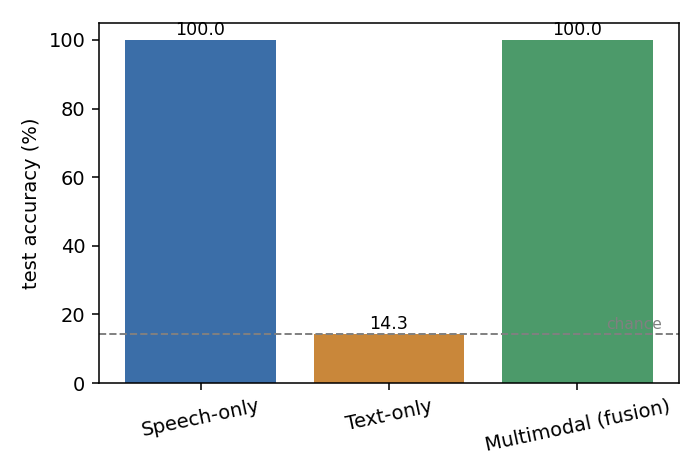

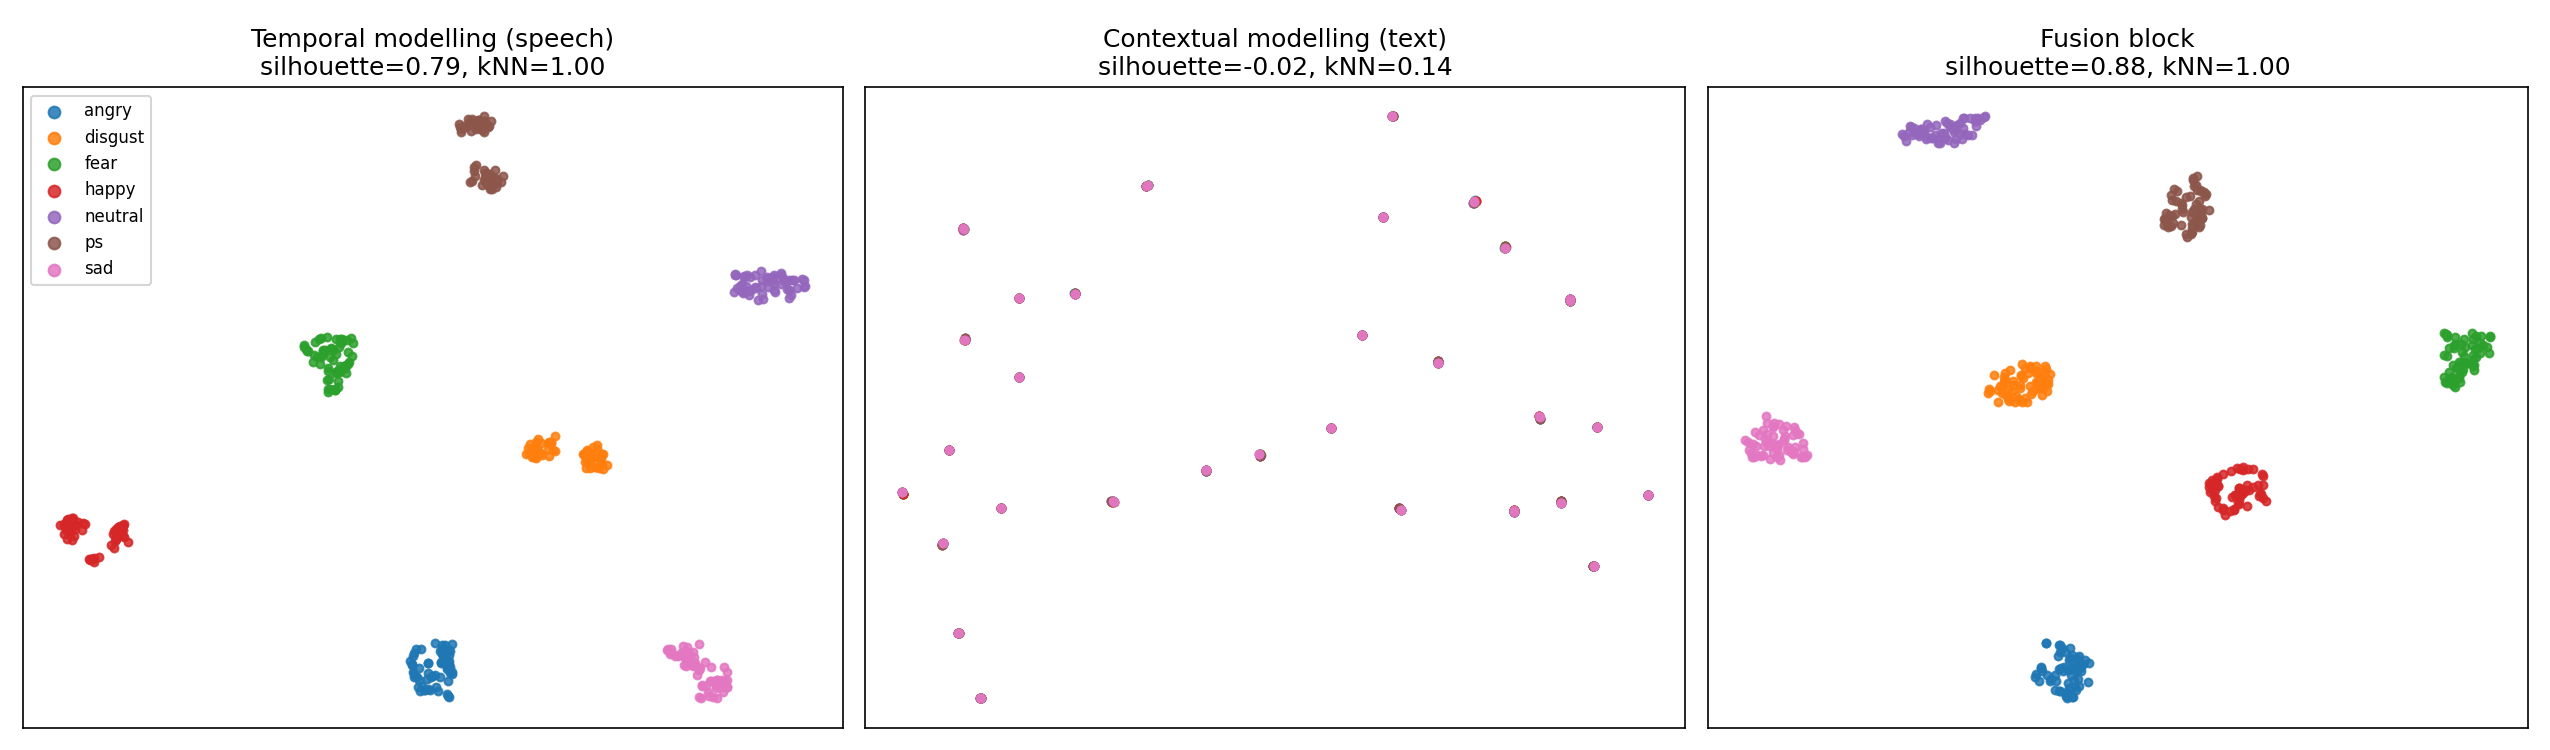

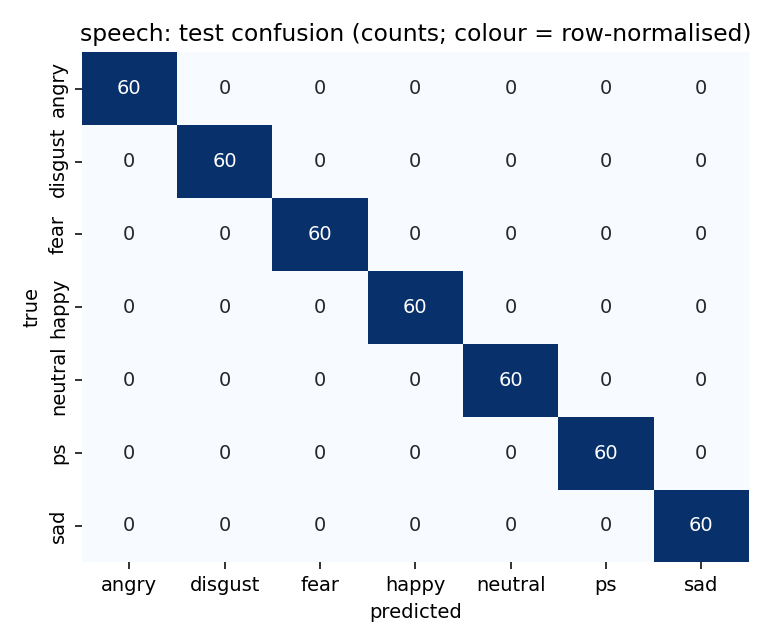

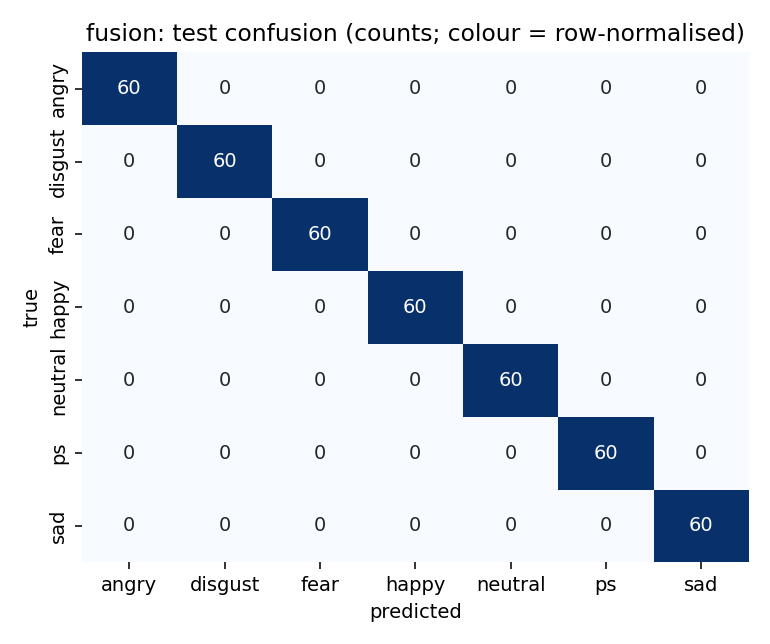

### Speech-only  (0 errors / 420)

| speaker   | word   | true   | pred   | confidence   |
|-----------|--------|--------|--------|--------------|

Most frequent confusions (true -> predicted): 

Errors by speaker:

| speaker   | correct     |
|:----------|:------------|
| OAF       | 0/210 wrong |
| YAF       | 0/210 wrong |

### Multimodal (fusion)  (0 errors / 420)

| speaker   | word   | true   | pred   | confidence   |
|-----------|--------|--------|--------|--------------|

Most frequent confusions (true -> predicted): 

### Text-only  (360 errors / 420)

| speaker   | word   | true    | pred   |   confidence |
|:----------|:-------|:--------|:-------|-------------:|
| OAF       | talk   | neutral | sad    |        0.144 |
| OAF       | talk   | ps      | sad    |        0.144 |
| YAF       | talk   | angry   | sad    |        0.144 |
| YAF       | talk   | disgust | sad    |        0.144 |
| OAF       | talk   | happy   | sad    |        0.144 |




In [19]:
from IPython.display import Image, display
print(open('Results/comparison/accuracy_table.md').read())
for f in ['comparison/accuracy_bar.png','comparison/tsne_all.png','speech/confusion_matrix.png','fusion/confusion_matrix.png']:
    display(Image('Results/'+f))
print(open('Results/comparison/failure_cases.md').read())

## 2. Speaker-independent baseline (train OAF, test unseen YAF; log-mel, no speaker norm)

In [20]:
S='--split speaker --test_speaker YAF --results_dir Results_speaker'
for p in ['speech','text','fusion']:
    !python models/{p}_pipeline/train.py {S}
    !python models/{p}_pipeline/test.py {S}
!python analyze.py --results_dir Results_speaker
print(open('Results_speaker/comparison/accuracy_table.md').read())

{'test': 1400, 'train': 1189, 'val': 210} | speakers: ['OAF', 'YAF']
[speech] params: 421,640 | device: cuda
[speech] ep 01 train 1.934/0.183 | val 1.888/0.386 | 2.7s
[speech] ep 02 train 1.686/0.472 | val 1.016/0.652 | 1.8s
[speech] ep 03 train 0.830/0.745 | val 0.167/0.967 | 1.8s
[speech] ep 04 train 0.505/0.909 | val 0.086/0.981 | 1.8s
[speech] ep 05 train 0.379/0.966 | val 0.058/0.995 | 1.8s
[speech] ep 06 train 0.341/0.980 | val 0.029/1.000 | 1.8s
[speech] ep 07 train 0.335/0.976 | val 0.038/0.990 | 1.8s
[speech] ep 08 train 0.333/0.976 | val 0.023/1.000 | 1.8s
[speech] ep 09 train 0.315/0.986 | val 0.035/1.000 | 1.8s
[speech] ep 10 train 0.308/0.988 | val 0.022/1.000 | 1.8s
[speech] ep 11 train 0.295/0.992 | val 0.020/1.000 | 1.8s
[speech] ep 12 train 0.306/0.991 | val 0.025/1.000 | 1.7s
[speech] ep 13 train 0.281/0.997 | val 0.022/1.000 | 1.8s
[speech] ep 14 train 0.285/0.997 | val 0.035/1.000 | 1.6s
[speech] ep 15 train 0.292/0.993 | val 0.035/1.000 | 1.6s
[speech] ep 16 train 

## 3. Configuration SELECTION on the reverse direction (train YAF -> test OAF)
YAF (the final test speaker) is never used as a *test* set here. The winner is picked automatically by OAF accuracy.

In [21]:
import json
variants = {'logmel':            '',
            'logmel+spk_norm':   '--spk_norm',
            'wavlm':             '--speech_feat wavlm',
            'wavlm+spk_norm':    '--speech_feat wavlm --spk_norm'}
sel = {}
for name, fl in variants.items():
    d = 'Select_' + name.replace('+','_')
    !python models/speech_pipeline/train.py --split speaker --test_speaker OAF --results_dir {d} {fl}
    !python models/speech_pipeline/test.py  --split speaker --test_speaker OAF --results_dir {d} {fl}
    m = json.load(open(f'{d}/speech/metrics.json')); sel[name] = (m['test_accuracy'], m['test_macro_f1'])
print('\nSELECTION (train YAF -> test OAF)')
for k,(a,f) in sel.items(): print(f'{k:18s} acc={a:.4f}  macroF1={f:.4f}')
BEST_NAME = max(sel, key=lambda k: sel[k][0]); BEST = variants[BEST_NAME]
print('\nSelected config:', BEST_NAME, '->', repr(BEST))

{'test': 1399, 'train': 1190, 'val': 210} | speakers: ['OAF', 'YAF']
[speech] params: 421,640 | device: cuda
[speech] ep 01 train 1.932/0.208 | val 1.884/0.571 | 2.7s
[speech] ep 02 train 1.696/0.621 | val 0.971/0.552 | 1.6s
[speech] ep 03 train 0.703/0.841 | val 0.036/0.995 | 1.7s
[speech] ep 04 train 0.377/0.975 | val 0.020/1.000 | 1.7s
[speech] ep 05 train 0.325/0.987 | val 0.030/0.995 | 1.7s
[speech] ep 06 train 0.305/0.991 | val 0.028/1.000 | 1.7s
[speech] ep 07 train 0.319/0.985 | val 0.019/1.000 | 1.8s
[speech] ep 08 train 0.301/0.990 | val 0.036/0.995 | 1.7s
[speech] ep 09 train 0.282/0.997 | val 0.051/0.986 | 1.8s
[speech] ep 10 train 0.278/0.999 | val 0.026/1.000 | 1.7s
[speech] ep 11 train 0.276/0.998 | val 0.031/1.000 | 1.8s
[speech] ep 12 train 0.273/0.999 | val 0.027/1.000 | 1.8s
[speech] ep 13 train 0.283/0.996 | val 0.031/1.000 | 1.8s
[speech] ep 14 train 0.271/1.000 | val 0.034/1.000 | 1.7s
[speech] ep 15 train 0.269/1.000 | val 0.030/1.000 | 1.6s
[speech] ep 16 train 

## 4. FINAL run (train OAF -> test YAF) with the auto-selected config. Run once; report this.

In [22]:
S = f'--split speaker --test_speaker YAF --results_dir Results_final {BEST}'
for p in ['speech','text','fusion']:
    !python models/{p}_pipeline/train.py {S}
    !python models/{p}_pipeline/test.py {S}
!python analyze.py --results_dir Results_final
print('Config:', BEST_NAME); print(open('Results_final/comparison/accuracy_table.md').read())

{'test': 1400, 'train': 1189, 'val': 210} | speakers: ['OAF', 'YAF']
[speech] params: 872,200 | device: cuda
[speech] ep 01 train 1.924/0.231 | val 1.842/0.519 | 5.9s
[speech] ep 02 train 1.554/0.608 | val 0.723/0.857 | 5.6s
[speech] ep 03 train 0.637/0.868 | val 0.129/0.957 | 5.6s
[speech] ep 04 train 0.359/0.983 | val 0.083/0.986 | 5.5s
[speech] ep 05 train 0.307/0.989 | val 0.031/1.000 | 5.7s
[speech] ep 06 train 0.303/0.989 | val 0.021/1.000 | 5.5s
[speech] ep 07 train 0.278/1.000 | val 0.022/1.000 | 5.6s
[speech] ep 08 train 0.285/0.994 | val 0.025/1.000 | 5.6s
[speech] ep 09 train 0.278/0.997 | val 0.026/1.000 | 5.6s
[speech] ep 10 train 0.279/0.997 | val 0.031/1.000 | 5.7s
[speech] ep 11 train 0.273/1.000 | val 0.026/1.000 | 5.7s
[speech] ep 12 train 0.269/1.000 | val 0.031/1.000 | 5.6s
[speech] ep 13 train 0.269/1.000 | val 0.025/1.000 | 5.6s
[speech] ep 14 train 0.269/1.000 | val 0.024/1.000 | 5.6s
[speech] ep 15 train 0.282/0.996 | val 0.032/1.000 | 5.1s
[speech] ep 16 train 

## 5. Ablation on YAF (for transparency ONLY: not used for selection; label it as such in the report)

In [23]:
abl = {}
for name, fl in variants.items():
    d = 'Ablation_' + name.replace('+','_')
    !python models/speech_pipeline/train.py --split speaker --test_speaker YAF --results_dir {d} {fl}
    !python models/speech_pipeline/test.py  --split speaker --test_speaker YAF --results_dir {d} {fl}
    m = json.load(open(f'{d}/speech/metrics.json')); abl[name] = (m['test_accuracy'], m['test_macro_f1'])
print('\nABLATION on YAF test (speech-only)')
for k,(a,f) in abl.items(): print(f'{k:18s} acc={a:.4f}  macroF1={f:.4f}' + ('   <- selected on OAF' if k==BEST_NAME else ''))

{'test': 1400, 'train': 1189, 'val': 210} | speakers: ['OAF', 'YAF']
[speech] params: 421,640 | device: cuda
[speech] ep 01 train 1.934/0.183 | val 1.888/0.386 | 2.5s
[speech] ep 02 train 1.686/0.472 | val 1.016/0.652 | 1.6s
[speech] ep 03 train 0.830/0.745 | val 0.167/0.967 | 1.6s
[speech] ep 04 train 0.505/0.909 | val 0.086/0.981 | 1.7s
[speech] ep 05 train 0.379/0.966 | val 0.060/0.990 | 1.7s
[speech] ep 06 train 0.341/0.981 | val 0.030/1.000 | 1.7s
[speech] ep 07 train 0.343/0.976 | val 0.039/0.995 | 1.7s
[speech] ep 08 train 0.341/0.975 | val 0.051/0.986 | 1.8s
[speech] ep 09 train 0.317/0.986 | val 0.033/1.000 | 1.7s
[speech] ep 10 train 0.309/0.989 | val 0.023/1.000 | 1.6s
[speech] ep 11 train 0.295/0.992 | val 0.034/0.995 | 1.6s
[speech] ep 12 train 0.301/0.989 | val 0.023/1.000 | 1.6s
[speech] ep 13 train 0.281/0.997 | val 0.033/0.995 | 1.7s
[speech] ep 14 train 0.280/0.999 | val 0.033/1.000 | 1.6s
[speech] ep 15 train 0.287/0.995 | val 0.040/1.000 | 1.6s
[speech] ep 16 train 

In [24]:
import json, numpy as np
%cd /kaggle/working/project

SEEDS = [1, 2, 3, 4, 5]
configs = {'logmel':          '',
           'wavlm':           '--speech_feat wavlm',
           'wavlm+spk_norm':  '--speech_feat wavlm --spk_norm'}
FINAL = 'wavlm+spk_norm'          # fusion is run for this config only
runs = {}                          # (model, config) -> list of accuracies

for seed in SEEDS:
    for name, fl in configs.items():
        d = f"Seeds_{name.replace('+','_')}_s{seed}"
        S = f"--split speaker --test_speaker YAF --seed {seed} --results_dir {d} {fl}"
        !python models/speech_pipeline/train.py {S}
        !python models/speech_pipeline/test.py  {S}
        runs.setdefault(('speech', name), []).append(
            json.load(open(f'{d}/speech/metrics.json'))['test_accuracy'])
        if name == FINAL:
            !python models/fusion_pipeline/train.py {S}
            !python models/fusion_pipeline/test.py  {S}
            runs.setdefault(('fusion', name), []).append(
                json.load(open(f'{d}/fusion/metrics.json'))['test_accuracy'])

print(f"\nTrain OAF -> test YAF, seeds {SEEDS} (accuracy %, mean ± std)")
for (model, name), v in runs.items():
    v = np.array(v) * 100
    print(f"{model:7s} {name:16s} {v.mean():6.2f} ± {v.std(ddof=1):5.2f}   runs: {np.round(v,2).tolist()}")

/kaggle/working/project
{'test': 1400, 'train': 1189, 'val': 210} | speakers: ['OAF', 'YAF']
[speech] params: 421,640 | device: cuda
[speech] ep 01 train 1.933/0.197 | val 1.886/0.419 | 2.4s
[speech] ep 02 train 1.704/0.447 | val 1.065/0.571 | 1.5s
[speech] ep 03 train 0.959/0.684 | val 0.290/0.890 | 1.5s
[speech] ep 04 train 0.567/0.895 | val 0.153/0.962 | 1.7s
[speech] ep 05 train 0.416/0.951 | val 0.096/0.976 | 1.7s
[speech] ep 06 train 0.395/0.957 | val 0.083/0.990 | 1.6s
[speech] ep 07 train 0.364/0.967 | val 0.029/0.995 | 1.6s
[speech] ep 08 train 0.333/0.981 | val 0.089/0.986 | 1.7s
[speech] ep 09 train 0.319/0.985 | val 0.083/0.986 | 1.6s
[speech] ep 10 train 0.310/0.984 | val 0.070/0.986 | 1.5s
[speech] ep 11 train 0.299/0.993 | val 0.038/0.995 | 1.6s
[speech] ep 12 train 0.295/0.992 | val 0.031/0.995 | 1.4s
[speech] ep 13 train 0.297/0.991 | val 0.076/0.990 | 1.5s
[speech] ep 14 train 0.309/0.987 | val 0.038/0.990 | 1.4s
[speech] ep 15 train 0.282/0.998 | val 0.035/1.000 | 1.

In [25]:

import json
import numpy as np
from pathlib import Path

%cd /kaggle/working/project

SEEDS = [1, 2, 3, 4, 5]

configs = {
    'logmel': '',
    'wavlm': '--speech_feat wavlm',
    'wavlm+spk_norm': '--speech_feat wavlm --spk_norm'
}

output = Path('/kaggle/working/Seeds_YAF_to_OAF')
output.mkdir(parents=True, exist_ok=True)

rev = {}

for seed in SEEDS:
    for name, fl in configs.items():

        d = output / f"SeedsRev_{name.replace('+','_')}_s{seed}"
        S = f"--split speaker --test_speaker OAF --seed {seed} --results_dir {d} {fl}"

        print(f"\nRunning {name}, seed {seed}")

        !python models/speech_pipeline/train.py {S}
        !python models/speech_pipeline/test.py {S}

        metrics_path = d / "speech" / "metrics.json"

        with open(metrics_path) as f:
            metrics = json.load(f)

        rev.setdefault(name, []).append(metrics['test_accuracy'])

print(f"\nTrain YAF -> test OAF, seeds {SEEDS}")
summary = {}

for name, values in rev.items():
    v = np.array(values) * 100

    summary[name] = {
        "mean_accuracy": float(v.mean()),
        "std_accuracy": float(v.std(ddof=1)),
        "per_seed_accuracy": v.tolist()
    }

    print(f"{name:16s} {v.mean():6.2f} ± {v.std(ddof=1):5.2f} "
          f"Runs: {np.round(v,2).tolist()}")

with open(output / "summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("\nALL EXPERIMENTS COMPLETED!")
print("Saved at:", output)


/kaggle/working/project

Running logmel, seed 1
{'test': 1399, 'train': 1190, 'val': 210} | speakers: ['OAF', 'YAF']
[speech] params: 421,640 | device: cuda
[speech] ep 01 train 1.934/0.192 | val 1.889/0.367 | 2.3s
[speech] ep 02 train 1.691/0.555 | val 0.918/0.838 | 1.4s
[speech] ep 03 train 0.711/0.865 | val 0.072/0.990 | 1.5s
[speech] ep 04 train 0.362/0.980 | val 0.024/1.000 | 1.5s
[speech] ep 05 train 0.333/0.982 | val 0.040/0.990 | 1.5s
[speech] ep 06 train 0.317/0.984 | val 0.026/0.995 | 1.5s
[speech] ep 07 train 0.303/0.993 | val 0.026/1.000 | 1.5s
[speech] ep 08 train 0.288/0.996 | val 0.034/0.995 | 1.6s
[speech] ep 09 train 0.288/0.995 | val 0.026/1.000 | 1.5s
[speech] ep 10 train 0.280/0.998 | val 0.024/1.000 | 1.6s
[speech] ep 11 train 0.288/0.997 | val 0.023/1.000 | 1.5s
[speech] ep 12 train 0.271/1.000 | val 0.024/1.000 | 1.5s
[speech] ep 13 train 0.275/0.998 | val 0.054/0.990 | 1.4s
[speech] ep 14 train 0.277/0.997 | val 0.033/1.000 | 1.5s
[speech] ep 15 train 0.270/1.00

In [26]:
!cd /kaggle/working && zip -qr results.zip project/Results* project/Select_* project/Ablation_* project/Seeds_* project/SeedsRev_* project/README.md -x '*.pt' && ls -la /kaggle/working/results.zip

-rw-r--r-- 1 root root 111827313 Nov 19 20:12 /kaggle/working/results.zip


In [27]:

import json
import numpy as np
from pathlib import Path

%cd /kaggle/working/project

SEEDS = [1, 2, 3, 4, 5]

configs = {
    'logmel': '',
    'wavlm': '--speech_feat wavlm',
    'wavlm+spk_norm': '--speech_feat wavlm --spk_norm'
}

output = Path('/kaggle/working/Seeds_YAF_to_OAF')
output.mkdir(parents=True, exist_ok=True)

rev = {}

for seed in SEEDS:
    for name, fl in configs.items():

        d = output / f"SeedsRev_{name.replace('+','_')}_s{seed}"
        S = f"--split speaker --test_speaker OAF --seed {seed} --results_dir {d} {fl}"

        print(f"\nRunning {name}, seed {seed}")

        !python models/speech_pipeline/train.py {S}
        !python models/speech_pipeline/test.py {S}

        metrics_path = d / "speech" / "metrics.json"

        with open(metrics_path) as f:
            metrics = json.load(f)

        rev.setdefault(name, []).append(metrics['test_accuracy'])

print(f"\nTrain YAF -> test OAF, seeds {SEEDS}")
summary = {}

for name, values in rev.items():
    v = np.array(values) * 100

    summary[name] = {
        "mean_accuracy": float(v.mean()),
        "std_accuracy": float(v.std(ddof=1)),
        "per_seed_accuracy": v.tolist()
    }

    print(f"{name:16s} {v.mean():6.2f} ± {v.std(ddof=1):5.2f} "
          f"Runs: {np.round(v,2).tolist()}")

with open(output / "summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("\nALL EXPERIMENTS COMPLETED!")
print("Saved at:", output)


/kaggle/working/project

Running logmel, seed 1
{'test': 1399, 'train': 1190, 'val': 210} | speakers: ['OAF', 'YAF']
[speech] params: 421,640 | device: cuda
[speech] ep 01 train 1.934/0.192 | val 1.889/0.367 | 2.3s
[speech] ep 02 train 1.691/0.555 | val 0.918/0.838 | 1.4s
[speech] ep 03 train 0.711/0.865 | val 0.072/0.990 | 1.6s
[speech] ep 04 train 0.362/0.980 | val 0.024/1.000 | 1.4s
[speech] ep 05 train 0.333/0.982 | val 0.040/0.990 | 1.5s
[speech] ep 06 train 0.317/0.985 | val 0.025/0.995 | 1.5s
[speech] ep 07 train 0.303/0.992 | val 0.027/1.000 | 1.5s
[speech] ep 08 train 0.288/0.997 | val 0.031/1.000 | 1.5s
[speech] ep 09 train 0.287/0.994 | val 0.026/1.000 | 1.6s
[speech] ep 10 train 0.285/0.996 | val 0.027/0.995 | 1.5s
[speech] ep 11 train 0.283/0.996 | val 0.024/1.000 | 1.6s
[speech] ep 12 train 0.273/0.999 | val 0.025/1.000 | 1.5s
[speech] ep 13 train 0.277/0.997 | val 0.042/0.995 | 1.6s
[speech] ep 14 train 0.275/0.999 | val 0.038/1.000 | 1.6s
[speech] ep 15 train 0.269/1.00

In [28]:
import json, os, numpy as np
%cd /kaggle/working/project
assert os.path.exists("models/speech_pipeline/train.py"), "Run the setup (%%writefile) cells first"

SEEDS = [1, 2, 3, 4, 5]
configs = {'logmel':          '',
           'wavlm':           '--speech_feat wavlm',
           'wavlm+spk_norm':  '--speech_feat wavlm --spk_norm'}
rev = {}

for seed in SEEDS:
    for name, fl in configs.items():
        d = f"SeedsRev_{name.replace('+','_')}_s{seed}"
        S = f"--split speaker --test_speaker OAF --seed {seed} --results_dir {d} {fl}"
        !python models/speech_pipeline/train.py {S}
        !python models/speech_pipeline/test.py  {S}
        rev.setdefault(name, []).append(
            json.load(open(f'{d}/speech/metrics.json'))['test_accuracy'])

print(f"\nTrain YAF -> test OAF, seeds {SEEDS} (speech-only accuracy %, mean ± std)")
for name, v in rev.items():
    v = np.array(v) * 100
    print(f"{name:16s} {v.mean():6.2f} ± {v.std(ddof=1):5.2f}   runs: {np.round(v,2).tolist()}")

# zip straight away, in the same cell
!cd /kaggle/working && zip -qr seeds_yaf_oaf.zip project/SeedsRev_* -x '*.pt'
!ls -la /kaggle/working/seeds_yaf_oaf.zip
!unzip -l /kaggle/working/seeds_yaf_oaf.zip | tail -1

/kaggle/working/project
{'test': 1399, 'train': 1190, 'val': 210} | speakers: ['OAF', 'YAF']
[speech] params: 421,640 | device: cuda
[speech] ep 01 train 1.934/0.192 | val 1.889/0.367 | 2.2s
[speech] ep 02 train 1.691/0.555 | val 0.918/0.838 | 1.4s
[speech] ep 03 train 0.711/0.865 | val 0.072/0.990 | 1.5s
[speech] ep 04 train 0.362/0.980 | val 0.023/1.000 | 1.6s
[speech] ep 05 train 0.332/0.982 | val 0.040/0.990 | 1.5s
[speech] ep 06 train 0.316/0.985 | val 0.027/0.995 | 1.5s
[speech] ep 07 train 0.303/0.993 | val 0.026/1.000 | 1.6s
[speech] ep 08 train 0.287/0.997 | val 0.037/0.995 | 1.5s
[speech] ep 09 train 0.283/0.998 | val 0.026/1.000 | 1.5s
[speech] ep 10 train 0.281/0.996 | val 0.028/1.000 | 1.6s
[speech] ep 11 train 0.282/0.997 | val 0.025/1.000 | 1.5s
[speech] ep 12 train 0.280/0.998 | val 0.026/1.000 | 1.5s
[speech] ep 13 train 0.274/1.000 | val 0.042/0.995 | 1.5s
[speech] ep 14 train 0.278/0.997 | val 0.034/1.000 | 1.4s
[speech] ep 15 train 0.272/0.999 | val 0.040/1.000 | 1.